# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

Cells with the most confirmed fraud (city, day):
  Pune, day 19: 17
  Pune, day 18: 13
  Pune, day 20: 10
  Bengaluru, day 15: 4
  Bengaluru, day 24: 3


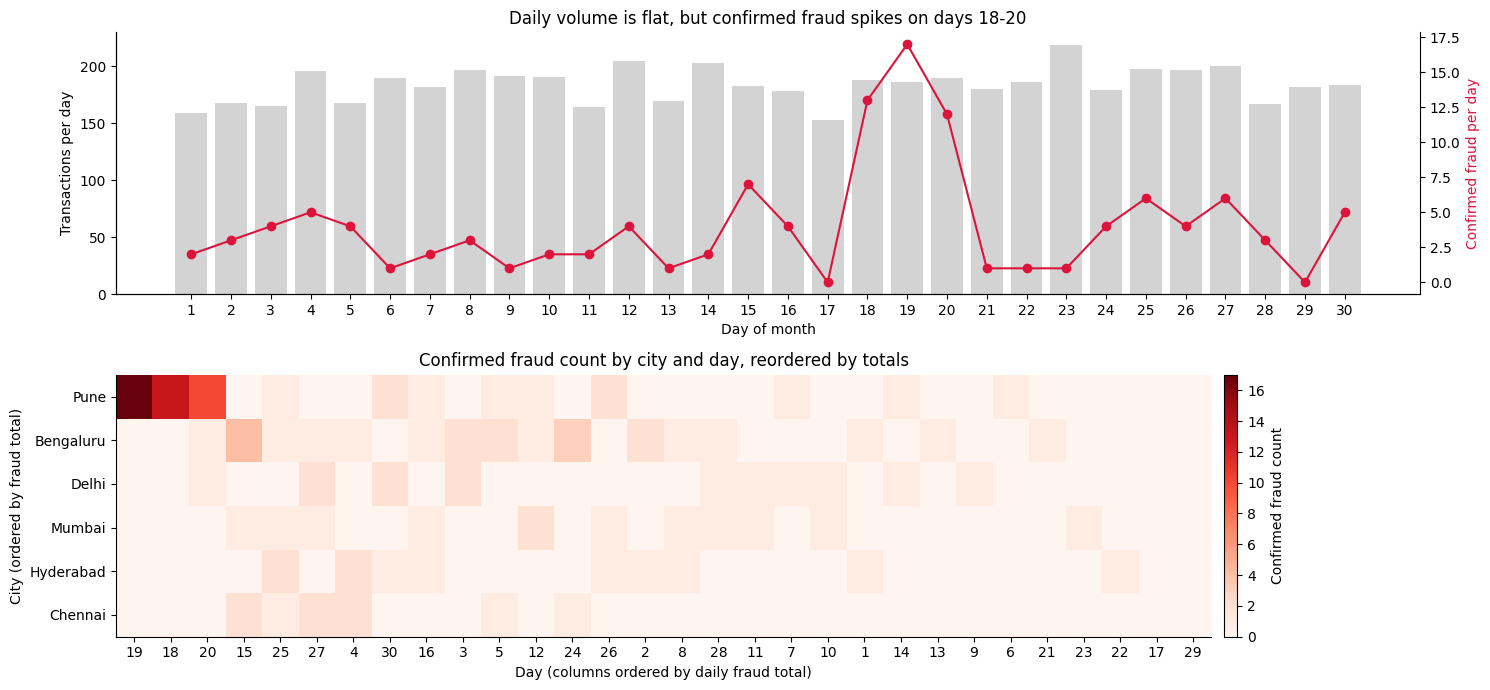

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily = tx.groupby("day").agg(n=("txn_id", "count"), fraud=("is_fraud", "sum"))
ax = axes[0]
ax.bar(daily.index, daily.n, color="lightgrey", label="All transactions")
ax.set_xlabel("Day of month"); ax.set_ylabel("Transactions per day")
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(daily.index, daily.fraud, "o-", color="crimson", label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud per day", color="crimson")
ax.set_title("Daily volume is flat, but confirmed fraud spikes on days 18-20")
ax.set_xticks(daily.index)

# TODO 2
cities = sorted(tx.city.unique())
heat = (tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="txn_id", aggfunc="count", fill_value=0)
        .reindex(index=cities, columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,            # rows by city total
                heat.sum(axis=0).sort_values(ascending=False).index]            # columns by day total
ax = axes[1]
im = ax.imshow(heat.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
ax.set_xlabel("Day (columns ordered by daily fraud total)"); ax.set_ylabel("City (ordered by fraud total)")
ax.set_title("Confirmed fraud count by city and day, reordered by totals")
fig.colorbar(im, ax=ax, label="Confirmed fraud count", pad=0.01)

plt.tight_layout(); plt.show()

# TODO 3
top = heat.stack().sort_values(ascending=False).head(5)
print("Cells with the most confirmed fraud (city, day):")
for (city, day), n in top.items():
    print(f"  {city}, day {day}: {n}")

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ Daily transaction volume is flat (about 150–220 per day), yet confirmed fraud jumps on days 18–20, and the reordered city × day heatmap shows that almost all of that jump is one block: **Pune, days 18–20**, which holds 40 of the 120 confirmed frauds (a third of the month's fraud). An alert list sorted by score ranks transactions one at a time, so it cannot show that many separate alerts share a city and a short time window. I found it through **overview first** with a **reordered matrix** (sorting rows and columns by their totals pushes the dense cells together so the block pattern pops out).

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

Brushed: 61 transactions | fraud rate inside brush 86.9% vs overall 2.2% (40x) | share of ALL fraud captured: 44.2% (53 of 120)


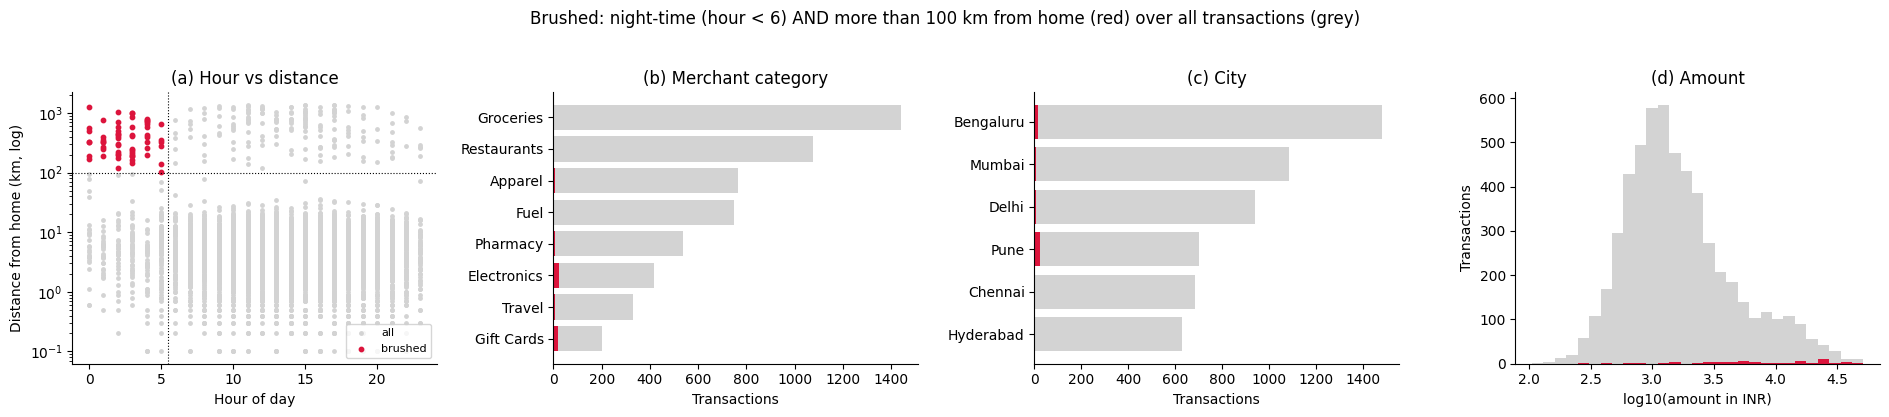

In [3]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
a, b_, c_, d = axes
a.scatter(tx.hour, tx.distance_from_home_km.clip(lower=0.1), s=6, color="lightgrey", label="all")
a.scatter(tx.hour[brush], tx.distance_from_home_km[brush].clip(lower=0.1), s=10, color="crimson", label="brushed")
a.set_yscale("log"); a.axvline(5.5, color="k", ls=":", lw=0.8); a.axhline(100, color="k", ls=":", lw=0.8)
a.set_xlabel("Hour of day"); a.set_ylabel("Distance from home (km, log)"); a.set_title("(a) Hour vs distance"); a.legend(loc="lower right", fontsize=8)

for ax, col, ttl in [(b_, "merchant_category", "(b) Merchant category"), (c_, "city", "(c) City")]:
    allc = tx[col].value_counts()
    brc = tx.loc[brush, col].value_counts().reindex(allc.index, fill_value=0)
    ax.barh(allc.index, allc.values, color="lightgrey"); ax.barh(brc.index, brc.values, color="crimson")
    ax.invert_yaxis(); ax.set_xlabel("Transactions"); ax.set_title(ttl)

bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
d.hist(np.log10(tx.amount_inr), bins=bins, color="lightgrey")
d.hist(np.log10(tx.amount_inr[brush]), bins=bins, color="crimson")
d.set_xlabel("log10(amount in INR)"); d.set_ylabel("Transactions"); d.set_title("(d) Amount")
fig.suptitle("Brushed: night-time (hour < 6) AND more than 100 km from home (red) over all transactions (grey)", y=1.03)

plt.tight_layout(); plt.show()

# TODO 3
n_brush = int(brush.sum())
rate_in = tx.is_fraud[brush].mean(); rate_all = tx.is_fraud.mean()
capture = tx.is_fraud[brush].sum() / tx.is_fraud.sum()
print(f"Brushed: {n_brush} transactions | fraud rate inside brush {rate_in:.1%} vs overall {rate_all:.1%} "
      f"({rate_in / rate_all:.0f}x) | share of ALL fraud captured: {capture:.1%} "
      f"({int(tx.is_fraud[brush].sum())} of {int(tx.is_fraud.sum())})")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ Inside the brush 86.9% of transactions are fraud (about 40 times the overall 2.2%), but the brush contains only 53 of the 120 frauds, so it **captures just 44%** and misses 56%. A rule with a high rate can still have low coverage, so relying on it alone would let more than half of the fraud through; it is a good filter for what to look at first, not a complete detector. The **city view** hinted at where to look next: Pune is over-represented in the brushed items (25 of 61), and the category view shows the pattern is concentrated in Electronics and Gift Cards. Checking the fraud outside the brush shows the same city and categories, but at ordinary hours and distances, which is what led to the Pune days 18–20 cluster.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
runs = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    runs.append(time.perf_counter() - t0)
best_s = min(runs)

# TODO 2
per_item_us = best_s / len(big) * 1e6              # microseconds per row
max_rows = 0.1 / best_s * len(big)                 # rows filterable in 0.1 s

# TODO 3
t_50m = per_item_us * 1e-6 * 50_000_000            # linear scaling
skip_pct = max(0.0, 100 * (1 - 0.1 / t_50m))       # share of rows that must not be scanned

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 13.6 ms -> 0.0135 us/row -> max 7,404,625 rows in 0.1 s
50M rows -> 0.68 s; must skip 85.2% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ **Aggregation** (pre-computing binned counts or a data cube by hour, city, category and score bucket), or alternatively **sampling**, would let the slider read a few thousand pre-computed cells instead of scanning 50 million rows, so feedback stays within 0.1 s. The analyst loses the individual transactions and exactness: a bin cannot show a single odd case, thresholds can only fall on bin edges, and with sampling rare events such as fraud (about 2% of rows) can be under-represented or missed. Details would have to be fetched on demand for the selected bins.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

 threshold  alerts  TP   FP  FN  precision  recall    f1
      0.05    2012 114 1898   6      0.057   0.950 0.107
      0.10    1167 111 1056   9      0.095   0.925 0.172
      0.15     786 110  676  10      0.140   0.917 0.243
      0.20     596 106  490  14      0.178   0.883 0.296
      0.25     471 105  366  15      0.223   0.875 0.355
      0.30     401 104  297  16      0.259   0.867 0.399
      0.35     355 104  251  16      0.293   0.867 0.438
      0.40     319 104  215  16      0.326   0.867 0.474
      0.45     283 104  179  16      0.367   0.867 0.516
      0.50     260 101  159  19      0.388   0.842 0.532
      0.55     235  97  138  23      0.413   0.808 0.546
      0.60     215  96  119  24      0.447   0.800 0.573
      0.65     197  94  103  26      0.477   0.783 0.593
      0.70     189  93   96  27      0.492   0.775 0.602
      0.75     170  87   83  33      0.512   0.725 0.600
      0.80     144  84   60  36      0.583   0.700 0.636
      0.85     128  79   49  41

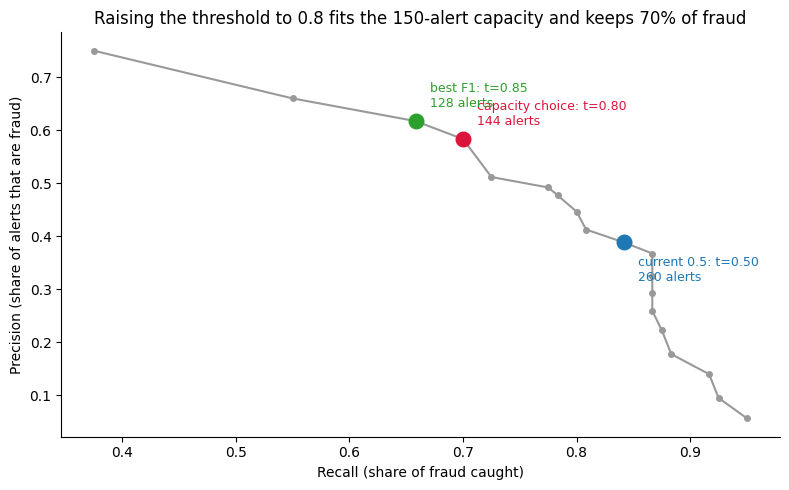

In [5]:
rows = []
# TODO 1
total_fraud = int(tx.is_fraud.sum())
for th in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flag = tx.detector_score >= th
    tp = int((flag & (tx.is_fraud == 1)).sum()); fp = int((flag & (tx.is_fraud == 0)).sum()); fn = total_fraud - tp
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn)
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    rows.append({"threshold": th, "alerts": tp + fp, "TP": tp, "FP": fp, "FN": fn, "precision": prec, "recall": rec, "f1": f1})

pr = pd.DataFrame(rows)

# TODO 2
within = pr[pr.alerts <= 150]
capacity_choice = within.loc[within.recall.idxmax()]       # highest recall among thresholds with <= 150 alerts
best_f1 = pr.loc[pr.f1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]
print(pr.round(3).to_string(index=False))

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="0.6", ms=4)
for lab, row, col in [("current 0.5", current, "tab:blue"), ("capacity choice", capacity_choice, "crimson"), ("best F1", best_f1, "tab:green")]:
    ax.scatter(row.recall, row.precision, s=110, color=col, zorder=3)
    ax.annotate(f"{lab}: t={row.threshold:.2f}\n{int(row.alerts)} alerts", (row.recall, row.precision),
                xytext=(10, -28 if lab == "current 0.5" else 10), textcoords="offset points", color=col, fontsize=9)
ax.set_xlabel("Recall (share of fraud caught)"); ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Raising the threshold to 0.8 fits the 150-alert capacity and keeps 70% of fraud")
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: set the threshold to {capacity_choice.threshold:.2f} ({int(capacity_choice.alerts)} alerts, "
      f"precision {capacity_choice.precision:.0%}, recall {capacity_choice.recall:.0%}); the current 0.5 gives {int(current.alerts)} alerts, "
      f"more than the team can review, and best F1 ({best_f1.threshold:.2f}) is close to it.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The **Head of Fraud Ops** should decide. F1 weighs a missed fraud and a false alarm equally, but the real costs are not equal or in the data: a missed fraud is money lost and a customer harmed, while a false alarm costs investigator time and customer friction, and only the business knows the 150-alert capacity and how much each error costs. The model only optimizes the metric it was given. Visual analytics keeps a human in the loop because the precision–recall view lets that person see the trade-off, steer the parameter with context the model does not have, and stay accountable for the decision.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [ ]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    color_discrete_map={"confirmed fraud": "crimson", "legitimate": "lightgrey"},
    hover_data={"txn_id": True, "customer_id": True, "city": True, "merchant_category": True,
                "distance_from_home_km": ":.0f", "detector_score": ":.2f", "timestamp": False, "amount_inr": ":,.0f"},
    title=f"{len(flagged)} transactions with detector score >= 0.3: hover for details, drag to select",
    labels={"amount_inr": "Amount (INR, log)", "timestamp": "Time"},
)
fig.update_layout(dragmode="select")
fig.show()

# TODO 2
g = (tx.groupby(["city", "merchant_category"])
       .agg(transactions=("txn_id", "count"), fraud_rate=("is_fraud", "mean")).reset_index())
sun = px.sunburst(g, path=["city", "merchant_category"], values="transactions", color="fraud_rate",
                  color_continuous_scale="Reds", title="Drill down: city to merchant category (size = transactions, colour = fraud rate)")
sun.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ A tooltip shows one point at a time, so to understand 400 cases the investigator would have to hover over each one and remember what they saw, which overloads working memory and makes comparison and pattern-finding almost impossible. Tooltips are for details on demand and are the wrong tool for overview. The **city × day heatmap** (or the linked-brushing dashboard, or the sunburst) fixes this by showing all cases at once so that clusters, such as Pune on days 18–20, are visible directly, and the tooltip is then used only to inspect the cases inside a cluster.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Inside window: 107 txns, 40 fraud (37.4%) | outside: 1.5% | chi-square p = 1.06e-136
  Pune days 18-20 (window)     n=  107 fraud= 40 rate=37.38%
  Pune, other days             n=  593 fraud= 11 rate=1.85%
  Other cities, days 18-20     n=  457 fraud=  2 rate=0.44%
  Everything else              n= 4363 fraud= 67 rate=1.54%
Verdict: SUPPORTED. The window's fraud rate is 25x the rest (p = 1.1e-136); neither counter-example (1.9% for Pune on other days, 0.4% for other cities on the same days) reproduces it, and the 40 frauds hit 40 different customers. 'Ring' is still unproven: this shows a localized, time-bound burst, and the window was chosen after looking at the data.


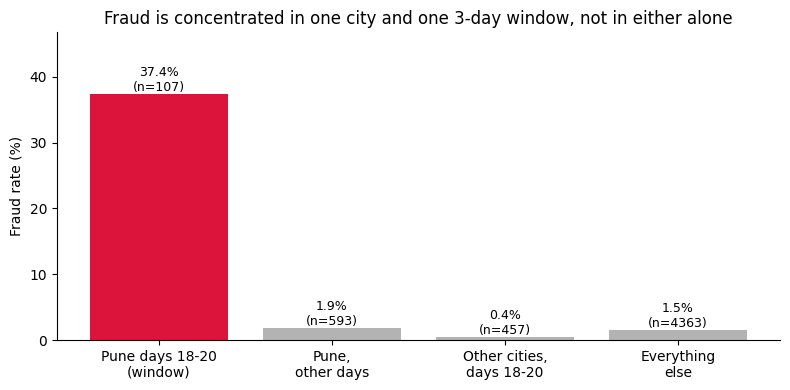

In [6]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# H: a coordinated fraud burst hit Pune on days 18-20 (the hot cell block in the Task 1 heatmap)
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
rate_in_w = tx.is_fraud[in_window].mean(); rate_out_w = tx.is_fraud[~in_window].mean()
chi2, p, _, _ = chi2_contingency(pd.crosstab(in_window, tx.is_fraud))
print(f"Inside window: {in_window.sum()} txns, {int(tx.is_fraud[in_window].sum())} fraud ({rate_in_w:.1%}) | "
      f"outside: {rate_out_w:.1%} | chi-square p = {p:.2e}")

# TODO 3
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = ~(in_window | same_city_other_days | other_cities_same_days)
groups = {"Pune days 18-20\n(window)": in_window, "Pune,\nother days": same_city_other_days,
          "Other cities,\ndays 18-20": other_cities_same_days, "Everything\nelse": rest}
rates = {k: tx.is_fraud[m].mean() for k, m in groups.items()}
for k, m in groups.items():
    print(f"  {k.replace(chr(10), ' '):28s} n={int(m.sum()):5d} fraud={int(tx.is_fraud[m].sum()):3d} rate={rates[k]:.2%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(list(rates), [v * 100 for v in rates.values()], color=["crimson", "0.7", "0.7", "0.7"])
for bar, (k, m) in zip(bars, groups.items()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f"{rates[k]:.1%}\n(n={int(m.sum())})", ha="center", fontsize=9)
ax.set_ylabel("Fraud rate (%)"); ax.set_ylim(0, max(rates.values()) * 100 * 1.25)
ax.set_title("Fraud is concentrated in one city and one 3-day window, not in either alone")
plt.tight_layout(); plt.show()

# TODO 5
cust = tx.loc[in_window & (tx.is_fraud == 1), "customer_id"].nunique()
print(f"Verdict: SUPPORTED. The window's fraud rate is {rate_in_w / rate_out_w:.0f}x the rest (p = {p:.1e}); neither counter-example "
      f"({rates['Pune,\nother days']:.1%} for Pune on other days, {rates['Other cities,\ndays 18-20']:.1%} for other cities on the same days) "
      f"reproduces it, and the {int(tx.is_fraud[in_window].sum())} frauds hit {cust} different customers. "
      f"'Ring' is still unproven: this shows a localized, time-bound burst, and the window was chosen after looking at the data.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ Both could have. If **other cities on the same days** had also shown a high fraud rate, the burst would not be about Pune but a time-based, nationwide event (such as a data breach or a change in the detector), and the "one city" claim would be dead. If **Pune on other days** had also been high, it would point to a chronic Pune problem, such as a compromised local merchant or terminal, rather than a short-lived ring. Neither happened: the rates were 0.4% and 1.9%, close to the 1.5% baseline, while the window was at 37%. That supports a localized burst, though a ring still needs evidence beyond rates, such as shared merchants or devices.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_ Of 5,520 transactions last month, 120 were confirmed fraud, and 40 of them (a third) hit 40 different customers in Pune on days 18–20, a 37% fraud rate against 1.5% elsewhere. I recommend raising the threshold from 0.5, which produces 260 alerts and is far more than the 150 we can review, to **0.80**, which gives 144 alerts at 58% precision and 70% recall; the best-F1 threshold (0.85) is almost the same, but the final trade-off between missed fraud and investigator time is your call, so the tool should let you steer it on the precision–recall view. The first interactive view to build is the **city × day overview heatmap with drill-down to the flagged cases**, because overview first is what exposed the Pune burst that a score-sorted alert list hid, and tooltips then give details on demand for the cases inside it. Since the night-time, far-from-home rule catches only 44% of fraud, it should be a filter and not the detector, and a dynamic filter must stay within the 0.1 s budget, which at 50 million rows means pre-aggregating. The feedback loop to add is to feed the investigators' confirmed labels back to retrain and recalibrate the detector each month, so that the next burst is scored higher.